# Notebook 04 — Tables, statistics and figures for the revised manuscript

**Requires:** Notebooks 01, 02 and 03 finished. **No training.** A CPU runtime is enough (≈ 10–15 min);
a GPU only speeds up the Grad-CAM figure (last step).

| Output | Reviewer comment |
|---|---|
| **Table 1** — all backbones × recipes: accuracy, balanced accuracy, macro precision / recall / F1, Cohen's κ, macro-AUC (mean ± SD over folds) and pooled accuracy with a 95 % bootstrap CI | R3-1, R4-1 (one consistent value), R3-5, R4-3 (CV) |
| **Table 2** — per-class precision / recall / F1 | R3-2 (per-class metrics) |
| **Table 3** — statistical comparisons: every model vs the best one, and recipe P vs B per backbone (McNemar exact test on the 1,720 paired predictions, paired bootstrap 95 % CI of the difference, Holm correction) | R4-3 (statistical analysis) |
| **Table 4** — ablation with paired differences, CIs and tests | R4-4 |
| **Table 5** — robustness under simulated field degradations | R1-3a |
| **Table 6** — leakage experiment | R4-6 |
| **Figures** — model comparison, confusion matrices, training/validation curves, per-class recall, ablation, robustness, leakage, Grad-CAM (300 dpi PNG + vector PDF) | R3-2, R3/R4-7 (figure quality) |
| `research_log_NB04.md` — every number at full precision | — |

**When finished:** send me the two small zips the last cell downloads (`NB04_results_text.zip`, `NB04_results_figures.zip`).
Together with all research logs and audit sheets, they are everything needed for Tier 2.

## 0. Settings

In [1]:
import os
NOTEBOOK, NB_TAG = "04_Analysis_Figures_Statistics", "NB04"
DRIVE_ROOT = os.environ.get("PEANUT_DRIVE_ROOT", "/content/drive/MyDrive/Peanut_Revision")
LOCAL_ROOT = os.environ.get("PEANUT_LOCAL_ROOT", "/content/peanut")

MAIN = ["resnet50__P", "resnet50__B", "efficientnet_b0__P", "efficientnet_b0__B",
        "efficientnet_b4__P", "efficientnet_b4__B", "convnext_base__P", "convnext_base__B"]
ABL_REF = "resnet50__P"
ABLATION = ["resnet50__P-no_aug", "resnet50__P-no_imbalance", "resnet50__P-loss_weights_only", "resnet50__P-sampler_only",
            "resnet50__P-no_scheduler", "resnet50__P-cosine", "resnet50__P-full_finetune", "resnet50__P-linear_head",
            "resnet50__vanilla_TL"]
LEAK_PAIRS = [("resnet50__P", "resnet50__P__naive_split"), ("convnext_base__B", "convnext_base__B__naive_split")]
GRADCAM_MODELS = ["resnet50__P", "efficientnet_b4__P"]    # need saved weights in 06_models (recipe-P runs)
N_BOOT = 10000
SEED = 2026
TEST_MODE = os.environ.get("PEANUT_TEST") == "1"
if TEST_MODE: N_BOOT = 500

## 1. Setup and loading every result

In [2]:
try:
    from google.colab import drive
    drive.mount("/content/drive"); IN_COLAB = True
except ImportError:
    IN_COLAB = False

import json, time, shutil, zipfile, io, platform, datetime as dt
from pathlib import Path
from dataclasses import dataclass, asdict, replace
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
import scipy, sklearn
from scipy.stats import binomtest, wilcoxon
from sklearn.metrics import confusion_matrix

D = {k: Path(DRIVE_ROOT) / v for k, v in {"data": "01_data", "splits": "02_splits", "audit": "03_audit", "results": "04_results",
     "models": "06_models", "figures": "07_figures", "tables": "08_tables", "logs": "09_logs"}.items()}
FIG, TAB = D["figures"] / "final", D["tables"] / "final"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

CLASSES = ["Alternaria leaf spot", "Healthy", "Leaf spot (early and late)", "Rosette", "Rust"]
SHORT = ["Alternaria", "Healthy", "Leaf spot", "Rosette", "Rust"]
NICE = {"resnet50": "ResNet-50", "efficientnet_b0": "EfficientNet-B0", "efficientnet_b4": "EfficientNet-B4", "convnext_base": "ConvNeXt-Base"}
ABL_NICE = {"resnet50__P": "Recipe P (reference)", "resnet50__P-no_aug": "No augmentation",
            "resnet50__P-no_imbalance": "No imbalance handling", "resnet50__P-loss_weights_only": "Loss weights only (no sampler)",
            "resnet50__P-sampler_only": "Sampler only (no loss weights)", "resnet50__P-no_scheduler": "Constant LR (no OneCycle)",
            "resnet50__P-cosine": "Cosine LR instead of OneCycle", "resnet50__P-full_finetune": "Full fine-tuning",
            "resnet50__P-linear_head": "Linear head", "resnet50__vanilla_TL": "Plain transfer learning"}
def nice(name):
    if name in ABL_NICE and name != "resnet50__P": return ABL_NICE[name]
    b, _, r = name.partition("__")
    return f"{NICE.get(b, b)} ({r.replace('_', ' ')})"

idx = pd.read_csv(D["splits"] / "index_original.csv")
cv_meta = json.loads((D["splits"] / "cv_splits_meta.json").read_text())
ENV = {"notebook": NOTEBOOK, "run_at": dt.datetime.now().isoformat(timespec="seconds"), "python": platform.python_version(),
       "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__, "scikit-learn": sklearn.__version__,
       "matplotlib": matplotlib.__version__}

def load(name):
    d = D["results"] / name
    runs = []
    for rd in sorted(d.glob("r*_f*")):
        if not (rd / "metrics.json").exists(): continue
        m = json.loads((rd / "metrics.json").read_text())
        pr = pd.read_csv(rd / "predictions.csv"); pr["fold"] = m["fold"]; pr["repeat"] = m["repeat"]
        lg = pd.read_csv(rd / "log.csv")
        rb = json.loads((rd / "robustness.json").read_text()) if (rd / "robustness.json").exists() else None
        runs.append({"m": m, "pred": pr, "log": lg, "rob": rb})
    return runs

ALL = {n: load(n) for n in dict.fromkeys(MAIN + [ABL_REF] + ABLATION + [x for p in LEAK_PAIRS for x in p])}
for n, r in ALL.items():
    print(f"{n:<34} {len(r)} folds" + ("" if r else "   <-- MISSING"))
MAIN = [n for n in MAIN if ALL[n]]; ABLATION = [n for n in ABLATION if ALL[n]]
LEAK_PAIRS = [p for p in LEAK_PAIRS if ALL[p[0]] and ALL[p[1]]]
GRADCAM_MODELS = [n for n in GRADCAM_MODELS if ALL.get(n)]

Mounted at /content/drive
resnet50__P                        5 folds
resnet50__B                        5 folds
efficientnet_b0__P                 5 folds
efficientnet_b0__B                 5 folds
efficientnet_b4__P                 5 folds
efficientnet_b4__B                 5 folds
convnext_base__P                   5 folds
convnext_base__B                   5 folds
resnet50__P-no_aug                 5 folds
resnet50__P-no_imbalance           5 folds
resnet50__P-loss_weights_only      5 folds
resnet50__P-sampler_only           5 folds
resnet50__P-no_scheduler           5 folds
resnet50__P-cosine                 5 folds
resnet50__P-full_finetune          5 folds
resnet50__P-linear_head            5 folds
resnet50__vanilla_TL               5 folds
resnet50__P__naive_split           5 folds
convnext_base__B__naive_split      5 folds


## 2. Statistics helpers

In [3]:
RNG = np.random.default_rng(SEED)
K = len(CLASSES)

def pooled(name):
    p = pd.concat([r["pred"] for r in ALL[name]], ignore_index=True)
    return p.sort_values(["repeat", "image_id"]).reset_index(drop=True)

def macro_f1_from_counts(cm):              # cm: (..., K, K)
    tp = np.diagonal(cm, axis1=-2, axis2=-1).astype(float)
    fp = cm.sum(-2) - tp; fn = cm.sum(-1) - tp
    denom = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, denom, out=np.zeros_like(tp), where=denom > 0)
    return f1.mean(-1)

def boot_indices(n):
    return RNG.integers(0, n, size=(N_BOOT, n))

def boot_metrics(y, p, B=None):
    # bootstrap distribution of accuracy and macro-F1 over images
    B = boot_indices(len(y)) if B is None else B
    acc = (y[B] == p[B]).mean(1)
    codes = y[B] * K + p[B]
    cm = np.stack([np.bincount(c, minlength=K * K) for c in codes]).reshape(-1, K, K)
    return acc, macro_f1_from_counts(cm)

def ci(a):
    return float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))

def holm(pvals):
    pvals = np.asarray(pvals, float); m = len(pvals); order = np.argsort(pvals); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, min(1.0, (m - rank) * pvals[i])); adj[i] = run
    return adj

def paired(a, b):
    # compare config a with config b on the same test images (pooled out-of-fold predictions)
    A, Bp = pooled(a), pooled(b)
    mm = A.merge(Bp, on=["repeat", "image_id"], suffixes=("_a", "_b"))
    y = mm["y_true_a"].to_numpy(int); pa = mm["y_pred_a"].to_numpy(int); pb = mm["y_pred_b"].to_numpy(int)
    ca, cb = pa == y, pb == y
    n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())
    p_mc = 1.0 if n01 + n10 == 0 else float(binomtest(n01, n01 + n10, 0.5).pvalue)
    Bi = boot_indices(len(y))
    acc_a, f1_a = boot_metrics(y, pa, Bi); acc_b, f1_b = boot_metrics(y, pb, Bi)
    fa = {r["m"]["fold"]: r["m"] for r in ALL[a]}; fb = {r["m"]["fold"]: r["m"] for r in ALL[b]}
    common = sorted(set(fa) & set(fb))
    d_fold = np.array([fa[f]["accuracy"] - fb[f]["accuracy"] for f in common])
    same_split = ALL[a][0]["m"]["config"].get("split", "cv_splits") == ALL[b][0]["m"]["config"].get("split", "cv_splits")
    p_w = float(wilcoxon(d_fold).pvalue) if same_split and len(d_fold) >= 5 and np.any(d_fold != 0) else float("nan")
    return {"A": a, "B": b, "n_images": int(len(y)), "acc_A": float(ca.mean()), "acc_B": float(cb.mean()),
            "diff_acc": float(ca.mean() - cb.mean()), "diff_acc_ci95": ci(acc_a - acc_b),
            "macroF1_A": float(macro_f1_from_counts(confusion_matrix(y, pa, labels=range(K)))),
            "macroF1_B": float(macro_f1_from_counts(confusion_matrix(y, pb, labels=range(K)))),
            "diff_macroF1_ci95": ci(f1_a - f1_b),
            "A_right_B_wrong": n01, "A_wrong_B_right": n10, "mcnemar_p": p_mc,
            "fold_diffs_acc": d_fold.tolist(), "wilcoxon_p_folds": p_w, "same_split": same_split}

def fold_stats(name, key):
    v = np.array([r["m"][key] for r in ALL[name] if key in r["m"]], float)
    return float(v.mean()), float(v.std(ddof=1)) if len(v) > 1 else 0.0

def pct(m, s, d=2): return f"{100*m:.{d}f} ± {100*s:.{d}f}"
EXACT = {}          # everything written to the research log at full precision

## 3. Table 1 — main comparison (replaces Table 7 of the manuscript)

In [4]:
rows, exact_rows = [], []
for n in MAIN:
    P = pooled(n); y, p = P["y_true"].to_numpy(int), P["y_pred"].to_numpy(int)
    acc_b, f1_b = boot_metrics(y, p)
    m0 = ALL[n][0]["m"]
    r = {"Backbone": NICE[m0["config"]["backbone"]], "Recipe": m0["config"]["recipe"],
         "Trainable params (M)": f"{m0['n_trainable_params']/1e6:.2f}"}
    e = {"configuration": n, "trainable_params": m0["n_trainable_params"], "total_params": m0["n_total_params"]}
    for k, lab in [("accuracy", "Accuracy (%)"), ("balanced_accuracy", "Balanced accuracy (%)"), ("macro_precision", "Macro precision (%)"),
                   ("macro_recall", "Macro recall (%)"), ("macro_f1", "Macro F1 (%)"), ("cohen_kappa", "Cohen's κ (×100)"),
                   ("macro_auc_ovr", "Macro AUC (×100)")]:
        mu, sd = fold_stats(n, k); r[lab] = pct(mu, sd); e[f"{k}_mean"], e[f"{k}_sd"] = mu, sd
    lo, hi = ci(acc_b); flo, fhi = ci(f1_b)
    r["Pooled accuracy % [95% CI]"] = f"{100*(y==p).mean():.2f} [{100*lo:.2f}, {100*hi:.2f}]"
    r["Correct / 1720"] = f"{int((y==p).sum())}/{len(y)}"
    r["Train min/fold"] = f"{np.mean([x['m']['train_minutes'] for x in ALL[n]]):.1f}"
    e.update({"pooled_correct": int((y == p).sum()), "pooled_n": int(len(y)), "pooled_accuracy": float((y == p).mean()),
              "pooled_accuracy_ci95": (lo, hi), "pooled_macro_f1": float(macro_f1_from_counts(confusion_matrix(y, p, labels=range(K)))),
              "pooled_macro_f1_ci95": (flo, fhi), "train_minutes_per_fold_mean": float(np.mean([x['m']['train_minutes'] for x in ALL[n]]))})
    rows.append(r); exact_rows.append(e)
T1 = pd.DataFrame(rows); T1_exact = pd.DataFrame(exact_rows)
T1.to_csv(TAB / "Table1_main_comparison.csv", index=False); T1_exact.to_csv(TAB / "Table1_main_comparison_EXACT.csv", index=False)
EXACT["Table 1 (exact)"] = T1_exact
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
display(T1)

,Backbone,Recipe,Trainable params (M),Accuracy (%),Balanced accuracy (%),Macro precision (%),Macro recall (%),Macro F1 (%),Cohen's κ (×100),Macro AUC (×100),Pooled accuracy % [95% CI],Correct / 1720,Train min/fold
0,ResNet-50,P,16.02,97.90 ± 0.65,97.90 ± 0.87,97.85 ± 0.99,97.90 ± 0.87,97.83 ± 0.62,97.14 ± 0.86,99.92 ± 0.02,"97.91 [97.21, 98.55]",1684/1720,3.8
1,ResNet-50,B,23.52,97.95 ± 0.35,98.26 ± 0.37,98.13 ± 0.88,98.26 ± 0.37,98.17 ± 0.52,97.20 ± 0.47,99.92 ± 0.05,"97.97 [97.27, 98.60]",1685/1720,4.8
2,EfficientNet-B0,P,3.81,97.45 ± 0.72,97.74 ± 1.34,97.79 ± 0.63,97.74 ± 1.34,97.72 ± 0.89,96.50 ± 1.03,99.87 ± 0.08,"97.44 [96.63, 98.20]",1676/1720,3.8
3,EfficientNet-B0,B,4.01,95.41 ± 0.77,94.27 ± 2.63,96.53 ± 0.72,94.27 ± 2.63,95.27 ± 1.78,93.71 ± 1.09,99.61 ± 0.10,"95.41 [94.42, 96.34]",1641/1720,4.5
4,EfficientNet-B4,P,14.83,98.67 ± 0.50,98.46 ± 1.22,98.74 ± 0.73,98.46 ± 1.22,98.57 ± 0.97,98.18 ± 0.71,99.97 ± 0.02,"98.66 [98.08, 99.19]",1697/1720,8.6
5,EfficientNet-B4,B,17.56,94.92 ± 0.99,89.78 ± 3.91,94.62 ± 1.07,89.78 ± 3.91,90.77 ± 4.00,93.00 ± 1.47,99.43 ± 0.31,"94.88 [93.84, 95.87]",1632/1720,10.1
6,ConvNeXt-Base,P,27.97,98.11 ± 0.99,98.24 ± 0.97,98.03 ± 0.55,98.24 ± 0.97,98.10 ± 0.59,97.42 ± 1.34,99.89 ± 0.06,"98.14 [97.50, 98.78]",1688/1720,5.5
7,ConvNeXt-Base,B,87.57,99.31 ± 0.42,99.10 ± 0.74,99.26 ± 0.41,99.10 ± 0.74,99.16 ± 0.52,99.05 ± 0.57,100.00 ± 0.00,"99.30 [98.90, 99.65]",1708/1720,8.8


## 4. Table 2 — per-class precision, recall and F1 (mean ± SD over folds)

In [5]:
rows, ex = [], []
for n in MAIN:
    for c, s in zip(CLASSES, SHORT):
        r = {"Model": nice(n), "Class": s}
        for k in ["precision", "recall", "f1"]:
            v = np.array([x["m"]["per_class"][c][k] for x in ALL[n]])
            r[k.capitalize() + " (%)"] = pct(v.mean(), v.std(ddof=1))
            ex.append({"configuration": n, "class": c, "metric": k, "mean": float(v.mean()), "sd": float(v.std(ddof=1)), "per_fold": v.tolist()})
        r["Support (pooled)"] = int(sum(x["m"]["per_class"][c]["support"] for x in ALL[n]))
        rows.append(r)
T2 = pd.DataFrame(rows); T2.to_csv(TAB / "Table2_per_class.csv", index=False)
EXACT["Table 2 (exact)"] = pd.DataFrame(ex); EXACT["Table 2 (exact)"].to_csv(TAB / "Table2_per_class_EXACT.csv", index=False)
display(T2.pivot(index="Model", columns="Class", values="Recall (%)"))

Class,Alternaria,Healthy,Leaf spot,Rosette,Rust
Model,,,,,
ConvNeXt-Base (B),98.86 ± 1.60,100.00 ± 0.00,98.86 ± 0.88,97.78 ± 3.04,100.00 ± 0.00
ConvNeXt-Base (P),97.28 ± 2.03,99.86 ± 0.31,96.27 ± 2.74,97.78 ± 3.04,100.00 ± 0.00
EfficientNet-B0 (B),96.47 ± 2.42,98.01 ± 2.24,91.87 ± 2.71,88.61 ± 10.41,96.40 ± 5.24
EfficientNet-B0 (P),95.24 ± 2.04,98.61 ± 1.42,97.05 ± 1.45,97.78 ± 4.97,100.00 ± 0.00
EfficientNet-B4 (B),94.16 ± 3.13,99.65 ± 0.48,95.26 ± 1.92,59.82 ± 18.46,100.00 ± 0.00
EfficientNet-B4 (P),98.19 ± 1.55,99.81 ± 0.42,97.61 ± 1.42,96.67 ± 4.97,100.00 ± 0.00
ResNet-50 (B),96.45 ± 0.88,100.00 ± 0.00,95.94 ± 2.03,98.89 ± 2.48,100.00 ± 0.00
ResNet-50 (P),96.85 ± 1.85,99.51 ± 0.46,96.47 ± 2.33,96.67 ± 4.97,100.00 ± 0.00


## 5. Table 3 — statistical comparisons
* **(a)** every configuration vs the best one (highest mean accuracy), Holm-corrected over the comparisons;
* **(b)** recipe P vs recipe B for each backbone, Holm-corrected over the four backbones.

McNemar's exact test uses the per-image correctness of the two models on the same 1,720 test images (each image is
tested once). The 95 % CI of the accuracy / macro-F1 difference comes from a paired bootstrap over images (10,000 resamples).
The Wilcoxon signed-rank test on the 5 fold accuracies is shown for completeness (with 5 folds its smallest possible two-sided p is 0.0625).

In [6]:
BEST = max(MAIN, key=lambda n: fold_stats(n, "accuracy")[0])
print("best configuration (mean fold accuracy):", BEST)
comp_a = [paired(BEST, n) for n in MAIN if n != BEST]
backbones = list(dict.fromkeys(ALL[n][0]["m"]["config"]["backbone"] for n in MAIN))
comp_b = [paired(f"{b}__P", f"{b}__B") for b in backbones if f"{b}__P" in MAIN and f"{b}__B" in MAIN]
def comp_table(comps, family):
    adj = holm([c["mcnemar_p"] for c in comps])
    rows = []
    for c, pa in zip(comps, adj):
        c["mcnemar_p_holm"] = float(pa); c["family"] = family
        rows.append({"Comparison": f"{nice(c['A'])} vs {nice(c['B'])}",
                     "Acc. A / B (%)": f"{100*c['acc_A']:.2f} / {100*c['acc_B']:.2f}",
                     "Δ acc. (pts) [95% CI]": f"{100*c['diff_acc']:+.2f} [{100*c['diff_acc_ci95'][0]:+.2f}, {100*c['diff_acc_ci95'][1]:+.2f}]",
                     "Δ macro-F1 (pts) [95% CI]": f"{100*(c['macroF1_A']-c['macroF1_B']):+.2f} [{100*c['diff_macroF1_ci95'][0]:+.2f}, {100*c['diff_macroF1_ci95'][1]:+.2f}]",
                     "A right, B wrong / A wrong, B right": f"{c['A_right_B_wrong']} / {c['A_wrong_B_right']}",
                     "McNemar p": f"{c['mcnemar_p']:.4g}", "Holm p": f"{pa:.4g}",
                     "Wilcoxon p (folds)": f"{c['wilcoxon_p_folds']:.4g}"})
    return pd.DataFrame(rows)
T3a, T3b = comp_table(comp_a, "vs best"), comp_table(comp_b, "P vs B")
T3a.to_csv(TAB / "Table3a_vs_best.csv", index=False); T3b.to_csv(TAB / "Table3b_recipe_P_vs_B.csv", index=False)
EXACT["Table 3 comparisons (exact)"] = comp_a + comp_b
print("(a) vs the best configuration"); display(T3a)
print("(b) recipe P vs recipe B"); display(T3b)

best configuration (mean fold accuracy): convnext_base__B
(a) vs the best configuration


,Comparison,Acc. A / B (%),Δ acc. (pts) [95% CI],Δ macro-F1 (pts) [95% CI],"A right, B wrong / A wrong, B right",McNemar p,Holm p,Wilcoxon p (folds)
0,ConvNeXt-Base (B) vs ResNet-50 (P),99.30 / 97.91,"+1.40 [+0.76, +2.09]","+1.29 [+0.58, +2.04]",29 / 5,3.856e-05,0.0001542,0.0625
1,ConvNeXt-Base (B) vs ResNet-50 (B),99.30 / 97.97,"+1.34 [+0.70, +2.03]","+0.97 [+0.37, +1.58]",28 / 5,6.619e-05,0.0001986,0.0625
2,ConvNeXt-Base (B) vs EfficientNet-B0 (P),99.30 / 97.44,"+1.86 [+1.16, +2.56]","+1.44 [+0.76, +2.16]",36 / 4,1.857e-07,9.285e-07,0.0625
3,ConvNeXt-Base (B) vs EfficientNet-B0 (B),99.30 / 95.41,"+3.90 [+2.91, +4.94]","+3.85 [+2.69, +5.13]",74 / 7,3.167e-15,1.9e-14,0.0625
4,ConvNeXt-Base (B) vs EfficientNet-B4 (P),99.30 / 98.66,"+0.64 [+0.12, +1.22]","+0.60 [+0.05, +1.18]",17 / 6,0.03469,0.03469,0.125
5,ConvNeXt-Base (B) vs EfficientNet-B4 (B),99.30 / 94.88,"+4.42 [+3.43, +5.47]","+7.92 [+6.03, +9.99]",81 / 5,9.579e-19,6.705e-18,0.0625
6,ConvNeXt-Base (B) vs ConvNeXt-Base (P),99.30 / 98.14,"+1.16 [+0.58, +1.80]","+1.03 [+0.43, +1.68]",24 / 4,0.00018,0.00036,0.0625


(b) recipe P vs recipe B


,Comparison,Acc. A / B (%),Δ acc. (pts) [95% CI],Δ macro-F1 (pts) [95% CI],"A right, B wrong / A wrong, B right",McNemar p,Holm p,Wilcoxon p (folds)
0,ResNet-50 (P) vs ResNet-50 (B),97.91 / 97.97,"-0.06 [-0.76, +0.64]","-0.31 [-1.08, +0.40]",19 / 20,1,1,0.875
1,EfficientNet-B0 (P) vs EfficientNet-B0 (B),97.44 / 95.41,"+2.03 [+0.99, +3.14]","+2.42 [+1.23, +3.66]",63 / 28,0.0003128,0.0006257,0.0625
2,EfficientNet-B4 (P) vs EfficientNet-B4 (B),98.66 / 94.88,"+3.78 [+2.79, +4.77]","+7.32 [+5.47, +9.34]",73 / 8,2.977e-14,1.191e-13,0.0625
3,ConvNeXt-Base (P) vs ConvNeXt-Base (B),98.14 / 99.30,"-1.16 [-1.74, -0.58]","-1.03 [-1.67, -0.42]",4 / 24,0.00018,0.00054,0.0625


## 6. Table 4 — ablation (ResNet-50, recipe P minus one component), paired against the reference

In [7]:
comp_abl = [paired(n, ABL_REF) for n in ABLATION]
adj = holm([c["mcnemar_p"] for c in comp_abl])
rows = []
for n, c, pa in zip(ABLATION, comp_abl, adj):
    c["mcnemar_p_holm"] = float(pa)
    mu, sd = fold_stats(n, "accuracy"); fmu, fsd = fold_stats(n, "macro_f1")
    d = np.array(c["fold_diffs_acc"])
    rob_n = [x["m"]["robustness"] for x in ALL[n] if "robustness" in x["m"]]
    rob_r = [x["m"]["robustness"] for x in ALL[ABL_REF] if "robustness" in x["m"]]
    deg = [k for k in (rob_n[0] if rob_n else {}) if k != "clean"]
    mean_deg = float(np.mean([np.mean([r[k] for k in deg]) for r in rob_n])) if rob_n else float("nan")
    rows.append({"Variant": ABL_NICE[n], "Accuracy (%)": pct(mu, sd), "Macro F1 (%)": pct(fmu, fsd),
                 "Δ acc. vs P (pts) [95% CI]": f"{100*c['diff_acc']:+.2f} [{100*c['diff_acc_ci95'][0]:+.2f}, {100*c['diff_acc_ci95'][1]:+.2f}]",
                 "Folds better/worse/equal": f"{int((d>0).sum())}/{int((d<0).sum())}/{int((d==0).sum())}",
                 "McNemar p (Holm)": f"{c['mcnemar_p']:.4g} ({pa:.4g})",
                 "Rosette recall (%)": f"{100*np.mean([x['m']['per_class']['Rosette']['recall'] for x in ALL[n]]):.1f}",
                 "Mean acc. over 9 degradations (%)": f"{100*mean_deg:.1f}" if rob_n else "-"})
ref_rob = [x["m"]["robustness"] for x in ALL[ABL_REF] if "robustness" in x["m"]]
deg = [k for k in ref_rob[0] if k != "clean"]
T4 = pd.DataFrame([{"Variant": ABL_NICE[ABL_REF], "Accuracy (%)": pct(*fold_stats(ABL_REF, "accuracy")),
                    "Macro F1 (%)": pct(*fold_stats(ABL_REF, "macro_f1")), "Δ acc. vs P (pts) [95% CI]": "—",
                    "Folds better/worse/equal": "—", "McNemar p (Holm)": "—",
                    "Rosette recall (%)": f"{100*np.mean([x['m']['per_class']['Rosette']['recall'] for x in ALL[ABL_REF]]):.1f}",
                    "Mean acc. over 9 degradations (%)": f"{100*np.mean([np.mean([r[k] for k in deg]) for r in ref_rob]):.1f}"}] + rows)
T4.to_csv(TAB / "Table4_ablation.csv", index=False)
EXACT["Table 4 ablation comparisons (exact)"] = comp_abl
display(T4)

,Variant,Accuracy (%),Macro F1 (%),Δ acc. vs P (pts) [95% CI],Folds better/worse/equal,McNemar p (Holm),Rosette recall (%),Mean acc. over 9 degradations (%)
0,Recipe P (reference),97.90 ± 0.65,97.83 ± 0.62,—,—,—,96.7,95.8
1,No augmentation,95.92 ± 1.69,95.77 ± 2.18,"-1.98 [-2.91, -1.10]",0/4/1,3.328e-05 (0.0002995),96.7,89.8
2,No imbalance handling,98.07 ± 0.77,98.09 ± 0.59,"+0.17 [-0.47, +0.81]",3/1/1,0.7201 (1),96.7,96.5
3,Loss weights only (no sampler),97.27 ± 1.55,96.91 ± 1.99,"-0.64 [-1.45, +0.17]",0/2/3,0.1608 (0.9647),96.7,95.4
4,Sampler only (no loss weights),96.82 ± 1.33,96.51 ± 1.51,"-1.10 [-1.86, -0.35]",0/4/1,0.006609 (0.05287),96.7,95.2
5,Constant LR (no OneCycle),97.52 ± 1.17,97.39 ± 1.23,"-0.41 [-1.10, +0.29]",2/3/0,0.3105 (1),93.3,95.3
6,Cosine LR instead of OneCycle,98.32 ± 0.45,98.19 ± 0.52,"+0.41 [-0.17, +0.99]",3/0/2,0.2478 (1),96.7,96.4
7,Full fine-tuning,98.01 ± 0.68,98.28 ± 0.75,"+0.12 [-0.58, +0.81]",2/3/0,0.8746 (1),97.8,96.8
8,Linear head,97.41 ± 1.37,97.69 ± 1.13,"-0.47 [-1.22, +0.29]",2/3/0,0.2912 (1),97.8,95.3
9,Plain transfer learning,97.16 ± 0.86,97.27 ± 0.92,"-0.76 [-1.51, +0.00]",1/3/1,0.07894 (0.5526),95.6,91.4


## 7. Table 5 — robustness to simulated field degradations (test accuracy, mean ± SD over folds)

In [8]:
ROB_MODELS = [n for n in MAIN if any("robustness" in x["m"] for x in ALL[n])] + \
             [n for n in ["resnet50__P-no_aug", "resnet50__vanilla_TL"] if n in ALL and ALL[n]]
PERTS = list(ALL[ROB_MODELS[0]][0]["m"]["robustness"])
rob_rows, rob_ex = {}, []
for n in ROB_MODELS:
    col = {}
    for k in PERTS:
        v = np.array([x["m"]["robustness"][k] for x in ALL[n]])
        col[k] = pct(v.mean(), v.std(ddof=1), 1)
        rob_ex.append({"configuration": n, "degradation": k, "mean": float(v.mean()), "sd": float(v.std(ddof=1)), "per_fold": v.tolist()})
    rob_rows[nice(n)] = col
T5 = pd.DataFrame(rob_rows); T5.index.name = "Degradation"
T5.to_csv(TAB / "Table5_robustness.csv"); EXACT["Table 5 robustness (exact)"] = pd.DataFrame(rob_ex)
display(T5)

,ResNet-50 (P),EfficientNet-B0 (P),EfficientNet-B4 (P),ConvNeXt-Base (P),No augmentation,Plain transfer learning
Degradation,,,,,,
clean,97.9 ± 0.6,97.4 ± 0.7,98.7 ± 0.5,98.1 ± 1.0,95.9 ± 1.7,97.2 ± 0.9
dark_0.6,97.0 ± 1.3,96.4 ± 0.9,98.7 ± 0.2,97.8 ± 1.4,92.0 ± 2.8,90.3 ± 2.1
overexposed_1.4,96.6 ± 0.9,95.7 ± 0.8,97.7 ± 1.4,96.8 ± 1.1,85.8 ± 6.4,91.0 ± 3.6
low_contrast_0.6,96.6 ± 1.1,96.9 ± 0.8,98.6 ± 0.5,97.9 ± 1.0,93.3 ± 2.5,92.0 ± 2.3
hard_shadow_0.4,94.8 ± 1.7,93.8 ± 1.5,98.2 ± 1.0,96.3 ± 0.5,89.6 ± 2.7,89.0 ± 3.2
blur_sigma2,96.3 ± 2.0,95.2 ± 2.7,97.3 ± 1.4,97.3 ± 1.1,90.8 ± 3.0,91.8 ± 2.9
noise_sd0.05,97.3 ± 1.5,96.9 ± 0.8,56.5 ± 10.8,97.2 ± 1.0,94.2 ± 2.2,95.9 ± 1.3
jpeg_q20,98.1 ± 0.3,97.2 ± 1.2,98.4 ± 0.6,96.9 ± 1.2,94.4 ± 1.3,96.5 ± 1.6
occlusion_25pct,87.9 ± 2.6,89.6 ± 1.6,93.2 ± 1.3,92.1 ± 1.0,74.2 ± 5.1,79.9 ± 8.5


## 8. Table 6 — leakage experiment (group-aware vs naive split)

In [9]:
GROUP = dict(zip(idx["image_id"], idx["dup_group"]))
naive = pd.read_csv(D["splits"] / "cv_splits_naive.csv")
leak = {}
for (r, f), s in naive.groupby(["repeat", "fold"]):
    tv = set(s.loc[s["role"] != "test", "image_id"].map(GROUP))
    for iid in s.loc[s["role"] == "test", "image_id"]:
        leak[(int(r), iid)] = GROUP[iid] in tv
rows, leak_ex = [], []
for g, nv in LEAK_PAIRS:
    c = paired(nv, g)
    P = pooled(nv); P["leaked"] = [leak[(int(r), i)] for r, i in zip(P["repeat"], P["image_id"])]
    P["ok"] = P["y_true"] == P["y_pred"]
    sub = {}
    for flag in (True, False):
        s_ = P[P["leaked"] == flag]; y, p = s_["y_true"].to_numpy(int), s_["y_pred"].to_numpy(int)
        a, _ = boot_metrics(y, p); sub[flag] = (int(s_["ok"].sum()), len(s_), float(s_["ok"].mean()), ci(a))
    rows.append({"Model": nice(g).replace(" (P)", ", recipe P").replace(" (B)", ", recipe B"),
                 "Group-aware acc. (%)": f"{100*c['acc_B']:.2f} ({int(round(c['acc_B']*c['n_images']))}/{c['n_images']})",
                 "Naive acc. (%)": f"{100*c['acc_A']:.2f} ({int(round(c['acc_A']*c['n_images']))}/{c['n_images']})",
                 "Inflation (pts) [95% CI]": f"{100*c['diff_acc']:+.2f} [{100*c['diff_acc_ci95'][0]:+.2f}, {100*c['diff_acc_ci95'][1]:+.2f}]",
                 "McNemar p": f"{c['mcnemar_p']:.4g}",
                 "Naive: images with near-duplicate in training": f"{sub[True][0]}/{sub[True][1]} = {100*sub[True][2]:.2f}%",
                 "Naive: images without": f"{sub[False][0]}/{sub[False][1]} = {100*sub[False][2]:.2f}%"})
    leak_ex.append({"group_aware": g, "naive": nv, "comparison": c,
                    "naive_with_duplicate": sub[True], "naive_without_duplicate": sub[False]})
T6 = pd.DataFrame(rows); T6.to_csv(TAB / "Table6_leakage.csv", index=False); EXACT["Table 6 leakage (exact)"] = leak_ex
display(T6)

,Model,Group-aware acc. (%),Naive acc. (%),Inflation (pts) [95% CI],McNemar p,Naive: images with near-duplicate in training,Naive: images without
0,"ResNet-50, recipe P",97.91 (1684/1720),99.13 (1705/1720),"+1.22 [+0.64, +1.86]",0.0001037,905/910 = 99.45%,800/810 = 98.77%
1,"ConvNeXt-Base, recipe B",99.30 (1708/1720),99.36 (1709/1720),"+0.06 [-0.29, +0.41]",1,910/910 = 100.00%,799/810 = 98.64%


## 9. Figures (300 dpi PNG + vector PDF, sized for a two-column journal page)
Colours: recipe **P** blue, recipe **B** orange (checked for colour-vision deficiency); every series also differs in marker
shape, and values are labelled where it matters, so no figure relies on colour alone.

font used: /usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf


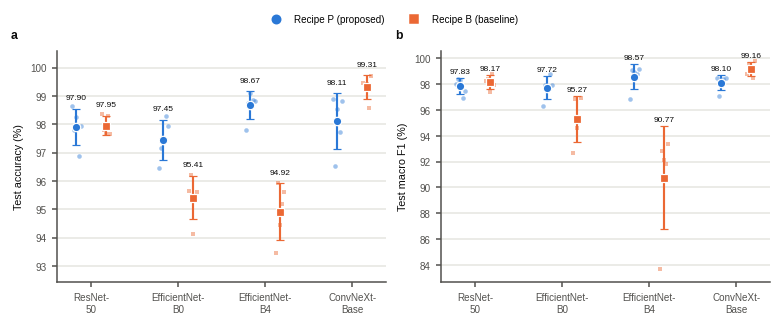

In [10]:
BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e6e5e0"
REC = {"P": (BLUE, "o"), "B": (ORANGE, "s")}
SEQ = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", "#cfe1f6", "#8dbaec", "#4a8fdf", "#1f63b8", "#123f7a"])
# Scientific Reports / Nature Portfolio artwork rules: sans-serif (Arial/Helvetica), 5-7 pt text, lines >= 1 pt,
# 180 mm double-column width, bold lower-case panel letters, 300 dpi bitmaps (TIFF/JPG) and vector files for charts.
if IN_COLAB:
    import subprocess
    subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-liberation"], capture_output=True)   # Liberation Sans = Arial metrics
    import matplotlib.font_manager as fm; fm._load_fontmanager(try_read_cache=False)
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
                     "font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7, "xtick.labelsize": 6.5, "ytick.labelsize": 6.5,
                     "legend.fontsize": 6.5, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.linewidth": 1.0, "xtick.major.width": 1.0, "ytick.major.width": 1.0,
                     "lines.linewidth": 1.4, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
                     "savefig.dpi": 300, "figure.dpi": 110, "savefig.bbox": "tight", "pdf.fonttype": 42, "ps.fonttype": 42})
W2 = 180 / 25.4     # double-column width (inches)
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300)                                           # review copy
    fig.savefig(FIG / f"{name}.pdf")                                                    # vector (charts)
    fig.savefig(FIG / f"{name}.tif", dpi=300, pil_kwargs={"compression": "tiff_lzw"})  # 300-dpi bitmap for submission
    plt.show(); plt.close(fig)
def ygrid(ax):
    ax.yaxis.grid(True, color=GRID, lw=1.0); ax.set_axisbelow(True)
def panel(ax, letter, x=-0.14, y=1.04):
    ax.text(x, y, letter, transform=ax.transAxes, fontsize=8, fontweight="bold", va="bottom", ha="left", color=INK)
print("font used:", matplotlib.font_manager.findfont(matplotlib.font_manager.FontProperties(family=["sans-serif"])))

# ---- Figure: model comparison (per-fold points + mean ± SD) ----
fig, axes = plt.subplots(1, 2, figsize=(W2, 2.8))
for pl, ax, key, lab in zip("ab", axes, ["accuracy", "macro_f1"], ["Test accuracy (%)", "Test macro F1 (%)"]):
    panel(ax, pl)
    for bi, b in enumerate(backbones):
        for off, rcp in [(-0.17, "P"), (0.17, "B")]:
            n = f"{b}__{rcp}"
            if n not in MAIN: continue
            v = 100 * np.array([x["m"][key] for x in ALL[n]]); col, mk = REC[rcp]
            ax.scatter(np.full(len(v), bi + off) + np.linspace(-0.05, 0.05, len(v)), v, s=9, color=col, alpha=0.45, lw=0, marker=mk, zorder=2)
            ax.errorbar(bi + off, v.mean(), yerr=v.std(ddof=1), fmt=mk, color=col, ms=5.5, mec="white", mew=0.8,
                        elinewidth=1.4, capsize=2.5, zorder=3)
            ax.text(bi + off, v.mean() + v.std(ddof=1) + 0.25, f"{v.mean():.2f}", ha="center", va="bottom", fontsize=5.5, color=INK)
    ax.set_xticks(range(len(backbones)), [NICE[b].replace("-", "-\n", 1) for b in backbones])
    ax.set_ylabel(lab); ygrid(ax)
    lo = min(100 * min(x["m"][key] for n in MAIN for x in ALL[n]), 100) - 1
    ax.set_ylim(max(lo, 0), 100.6)
h = [plt.Line2D([], [], color=BLUE, marker="o", ls="", ms=5.5, label="Recipe P (proposed)"),
     plt.Line2D([], [], color=ORANGE, marker="s", ls="", ms=5.5, label="Recipe B (baseline)")]
fig.legend(handles=h, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout(); save(fig, "Fig_model_comparison")

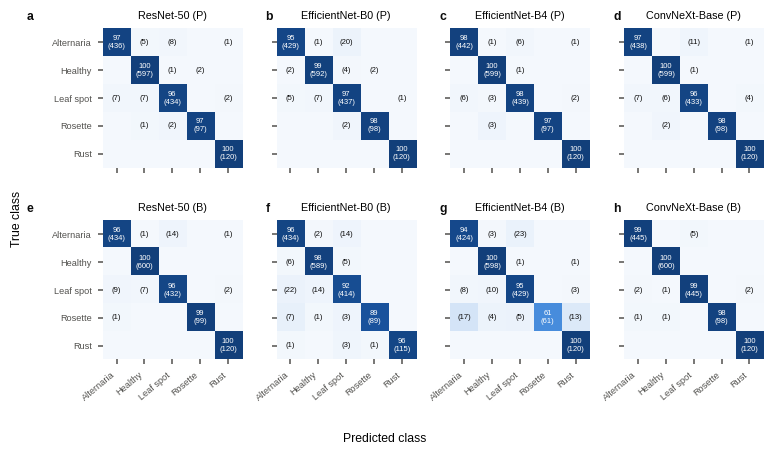

In [11]:
# ---- Figure: pooled confusion matrices (row-normalised %, counts in brackets) ----
nc = 4; nr = int(np.ceil(len(MAIN) / nc))
fig, axes = plt.subplots(nr, nc, figsize=(W2, 3.9 * nr / 2 + 0.3))
axes = np.atleast_2d(axes)
order = [f"{b}__{r}" for r in ("P", "B") for b in backbones if f"{b}__{r}" in MAIN]
for ax, n in zip(axes.flat, order):
    P = pooled(n); cm = confusion_matrix(P["y_true"], P["y_pred"], labels=range(K)); rp = cm / cm.sum(1, keepdims=True)
    ax.imshow(rp, cmap=SEQ, vmin=0, vmax=1)
    for i in range(K):
        for j in range(K):
            if cm[i, j] == 0: continue
            ax.text(j, i, f"{100*rp[i,j]:.0f}\n({cm[i,j]})" if i == j else f"({cm[i,j]})", ha="center", va="center",
                    fontsize=5, color="white" if rp[i, j] > 0.55 else INK)
    first_col, bottom = (list(axes.flat).index(ax) % nc == 0), (list(axes.flat).index(ax) >= (nr - 1) * nc)
    ax.set_xticks(range(K), SHORT if bottom else [""] * K, fontsize=6, rotation=40, ha="right")
    ax.set_yticks(range(K), SHORT if first_col else [""] * K, fontsize=6)
    ax.set_title(nice(n), fontsize=7)
    panel(ax, "abcdefgh"[list(axes.flat).index(ax)], x=-0.08 if not first_col else -0.55)
    for sp in ax.spines.values(): sp.set_visible(False)
for ax in axes.flat[len(order):]: ax.axis("off")
fig.supxlabel("Predicted class", fontsize=8); fig.supylabel("True class", fontsize=8)
fig.tight_layout(); save(fig, "Fig_confusion_matrices")

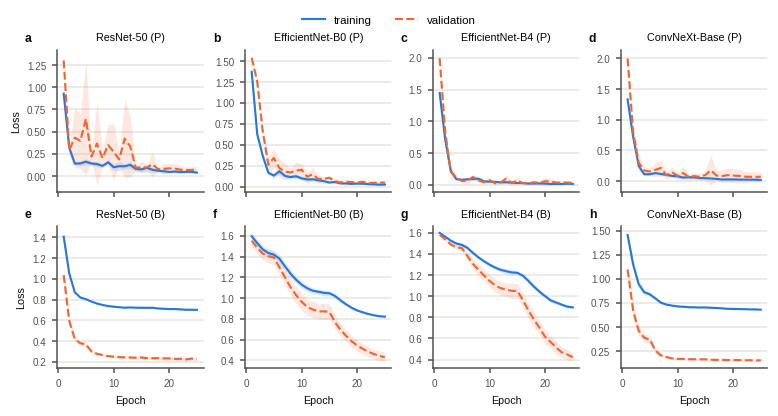

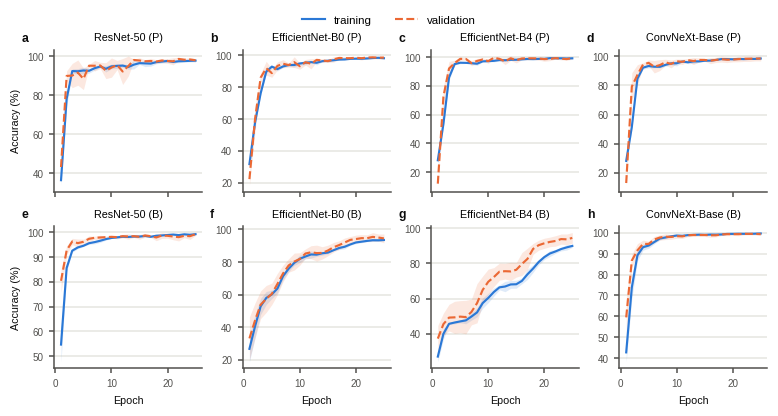

In [12]:
# ---- Figures: training and validation curves (mean ± SD over folds) ----
for metric, ylab, fname in [("loss", "Loss", "Fig_curves_loss"), ("acc", "Accuracy (%)", "Fig_curves_accuracy")]:
    fig, axes = plt.subplots(2, 4, figsize=(W2, 3.6), sharex=True)
    for pi, (ax, n) in enumerate(zip(axes.flat, order)):
        panel(ax, "abcdefgh"[pi], x=-0.22)
        Lmin = min(len(x["log"]) for x in ALL[n]); ep = np.arange(1, Lmin + 1)
        for split, col, ls in [("train", BLUE, "-"), ("val", ORANGE, "--")]:
            arr = np.stack([x["log"][f"{split}_{metric}"].values[:Lmin] for x in ALL[n]]) * (100 if metric == "acc" else 1)
            ax.plot(ep, arr.mean(0), color=col, lw=1.4, ls=ls, label="training" if split == "train" else "validation")
            ax.fill_between(ep, arr.mean(0) - arr.std(0), arr.mean(0) + arr.std(0), color=col, alpha=0.15, lw=0)
        ax.set_title(nice(n), fontsize=7); ygrid(ax)
    for ax in axes[:, 0]: ax.set_ylabel(ylab)
    for ax in axes[1]: ax.set_xlabel("Epoch")
    hh, ll = axes[0, 0].get_legend_handles_labels()
    fig.legend(hh, ll, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.04), fontsize=7.5)
    fig.tight_layout(); save(fig, fname)

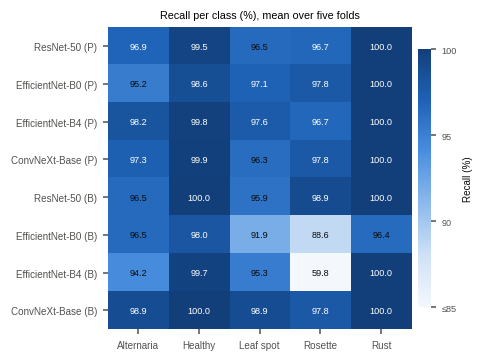

In [13]:
# ---- Figure: per-class recall heatmap ----
R = np.array([[100 * np.mean([x["m"]["per_class"][c]["recall"] for x in ALL[n]]) for c in CLASSES] for n in order])
VMIN = 85   # colour scale clipped at 85 % so differences between 90 and 100 % stay visible; every cell is labelled
fig, ax = plt.subplots(figsize=(4.4, 0.3 * len(order) + 0.9))
im = ax.imshow(np.clip(R, VMIN, 100), cmap=SEQ, vmin=VMIN, vmax=100, aspect="auto")
for i in range(R.shape[0]):
    for j in range(R.shape[1]):
        ax.text(j, i, f"{R[i,j]:.1f}", ha="center", va="center", fontsize=6, color="white" if R[i, j] > 96.5 else INK)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label("Recall (%)", fontsize=6.5); cb.ax.tick_params(labelsize=6)
cb.set_ticks([85, 90, 95, 100]); cb.set_ticklabels(["≤85", "90", "95", "100"]); cb.outline.set_visible(False)
ax.set_xticks(range(K), SHORT); ax.set_yticks(range(len(order)), [nice(n) for n in order])
ax.set_title("Recall per class (%), mean over five folds")
for sp in ax.spines.values(): sp.set_visible(False)
fig.tight_layout(); save(fig, "Fig_per_class_recall")

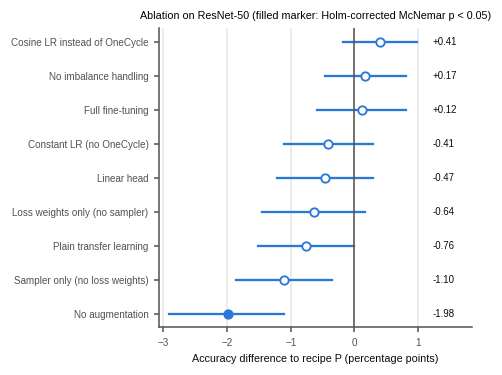

In [14]:
# ---- Figure: ablation (paired difference to recipe P, 95% bootstrap CI) ----
if comp_abl:
    lab = [ABL_NICE[c["A"]] for c in comp_abl]
    da = np.array([100 * c["diff_acc"] for c in comp_abl]); lo = np.array([100 * c["diff_acc_ci95"][0] for c in comp_abl]); hi = np.array([100 * c["diff_acc_ci95"][1] for c in comp_abl])
    o = np.argsort(da)
    fig, ax = plt.subplots(figsize=(4.4, 0.28 * len(lab) + 0.9))
    for k, i in enumerate(o):
        sig = comp_abl[i]["mcnemar_p_holm"] < 0.05
        ax.plot([lo[i], hi[i]], [k, k], color=BLUE, lw=1.5)
        ax.plot(da[i], k, marker="o", ms=5.5, color=BLUE if sig else "white", mec=BLUE, mew=1.2)
    span = max(hi.max(), 0) - min(lo.min(), 0); xr = max(hi.max(), 0) + 0.06 * span
    for k, i in enumerate(o):
        ax.text(xr, k, f"{da[i]:+.2f}", va="center", ha="left", fontsize=6.3, color=INK)
    ax.set_xlim(min(lo.min(), 0) - 0.04 * span, xr + 0.16 * span)
    ax.axvline(0, color=MUTED, lw=1.0)
    ax.set_yticks(range(len(lab)), [lab[i] for i in o]); ax.set_xlabel("Accuracy difference to recipe P (percentage points)")
    ax.set_title("Ablation on ResNet-50 (filled marker: Holm-corrected McNemar p < 0.05)", fontsize=7)
    ax.xaxis.grid(True, color=GRID, lw=1.0); ax.set_axisbelow(True)
    fig.tight_layout(); save(fig, "Fig_ablation")

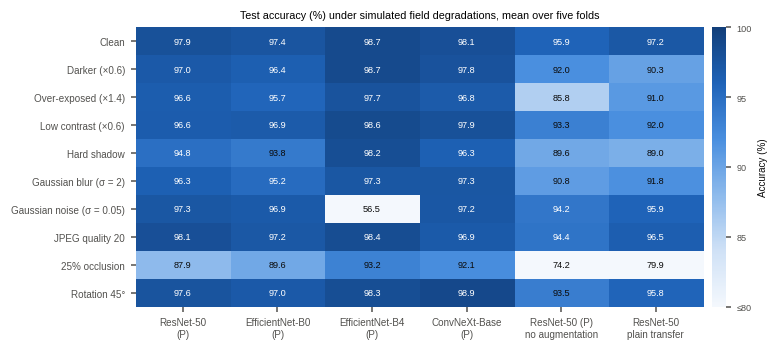

In [15]:
# ---- Figure: robustness heatmap (accuracy % per degradation) ----
NAMES_R = {"clean": "Clean", "dark_0.6": "Darker (×0.6)", "overexposed_1.4": "Over-exposed (×1.4)", "low_contrast_0.6": "Low contrast (×0.6)",
           "hard_shadow_0.4": "Hard shadow", "blur_sigma2": "Gaussian blur (σ = 2)", "noise_sd0.05": "Gaussian noise (σ = 0.05)",
           "jpeg_q20": "JPEG quality 20", "occlusion_25pct": "25% occlusion", "rotation_45": "Rotation 45°"}
Rb = np.array([[100 * np.mean([x["m"]["robustness"][k] for x in ALL[n]]) for n in ROB_MODELS] for k in PERTS])
VMIN_R = 80  # clipped at 80 % so differences above 90 % stay visible; every cell is labelled
fig, ax = plt.subplots(figsize=(W2, 3.2))
im = ax.imshow(np.clip(Rb, VMIN_R, 100), cmap=SEQ, vmin=VMIN_R, vmax=100, aspect="auto")
for i in range(Rb.shape[0]):
    for j in range(Rb.shape[1]):
        ax.text(j, i, f"{Rb[i,j]:.1f}", ha="center", va="center", fontsize=6, color="white" if Rb[i, j] > 94 else INK)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.015); cb.set_label("Accuracy (%)", fontsize=6.5); cb.ax.tick_params(labelsize=6)
cb.set_ticks([80, 85, 90, 95, 100]); cb.set_ticklabels(["≤80", "85", "90", "95", "100"]); cb.outline.set_visible(False)
ax.set_yticks(range(len(PERTS)), [NAMES_R.get(k, k) for k in PERTS])
ROB_LAB = {"resnet50__P-no_aug": "ResNet-50 (P)\nno augmentation", "resnet50__vanilla_TL": "ResNet-50\nplain transfer"}
ax.set_xticks(range(len(ROB_MODELS)), [ROB_LAB.get(n, nice(n).replace(" (", "\n(")) for n in ROB_MODELS], fontsize=6.5)
ax.set_title("Test accuracy (%) under simulated field degradations, mean over five folds", fontsize=7)
for sp in ax.spines.values(): sp.set_visible(False)
fig.tight_layout(); save(fig, "Fig_robustness")

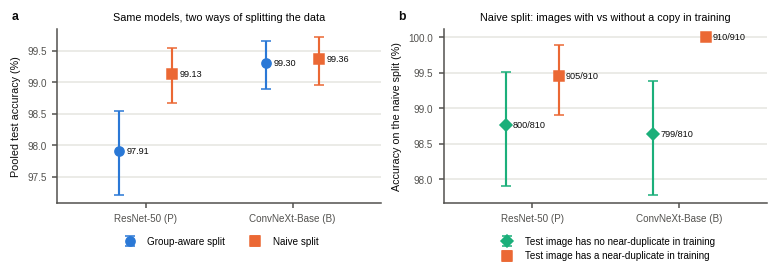

In [16]:
# ---- Figure: leakage ----
if leak_ex:
    fig, axes = plt.subplots(1, 2, figsize=(W2, 2.6))
    panel(axes[0], "a"); panel(axes[1], "b")
    ax = axes[0]; w = 0.36
    for k, e in enumerate(leak_ex):
        c = e["comparison"]
        for off, acc, col, mk, lab in [(-w/2, c["acc_B"], BLUE, "o", "Group-aware split"), (w/2, c["acc_A"], ORANGE, "s", "Naive split")]:
            P = pooled(e["group_aware"] if off < 0 else e["naive"]); a_, _ = boot_metrics(P["y_true"].to_numpy(int), P["y_pred"].to_numpy(int)); l, h = ci(a_)
            ax.errorbar(k + off, 100 * acc, yerr=[[100 * (acc - l)], [100 * (h - acc)]], fmt=mk, color=col, ms=6, capsize=3, elinewidth=1.4,
                        label=lab if k == 0 else None)
            ax.text(k + off + 0.05, 100 * acc, f"{100*acc:.2f}", ha="left", va="center", fontsize=6, color=INK)
    ax.set_xticks(range(len(leak_ex)), [nice(e["group_aware"]) for e in leak_ex]); ax.set_xlim(-0.6, len(leak_ex) - 0.4)
    ax.set_ylabel("Pooled test accuracy (%)"); ygrid(ax); ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
    ax.set_title("Same models, two ways of splitting the data", fontsize=7)
    ax = axes[1]
    for k, e in enumerate(leak_ex):
        for off, key, col, mk, lab in [(-w/2, "naive_without_duplicate", AQUA, "D", "Test image has no near-duplicate in training"),
                                       (w/2, "naive_with_duplicate", ORANGE, "s", "Test image has a near-duplicate in training")]:
            ok, nn_, acc, (l, h) = e[key]
            ax.errorbar(k + off, 100 * acc, yerr=[[100 * (acc - l)], [100 * (h - acc)]], fmt=mk, color=col, ms=6, capsize=3, elinewidth=1.4,
                        label=lab if k == 0 else None)
            ax.text(k + off + 0.05, 100 * acc, f"{ok}/{nn_}", ha="left", va="center", fontsize=6, color=INK)
    ax.set_xticks(range(len(leak_ex)), [nice(e["group_aware"]) for e in leak_ex]); ax.set_xlim(-0.6, len(leak_ex) - 0.4)
    ax.set_ylabel("Accuracy on the naive split (%)"); ygrid(ax)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=1, fontsize=6.5)
    ax.set_title("Naive split: images with vs without a copy in training", fontsize=7)
    fig.tight_layout(); save(fig, "Fig_leakage")

## 10. Grad-CAM: where do the models look?
Uses the saved fold-0 weights of the recipe-P models (`06_models/`). For each class: one test image that both models
classify correctly, plus up to four misclassified test images. Bright (yellow) = regions that most increased the predicted class score; dark = little influence.

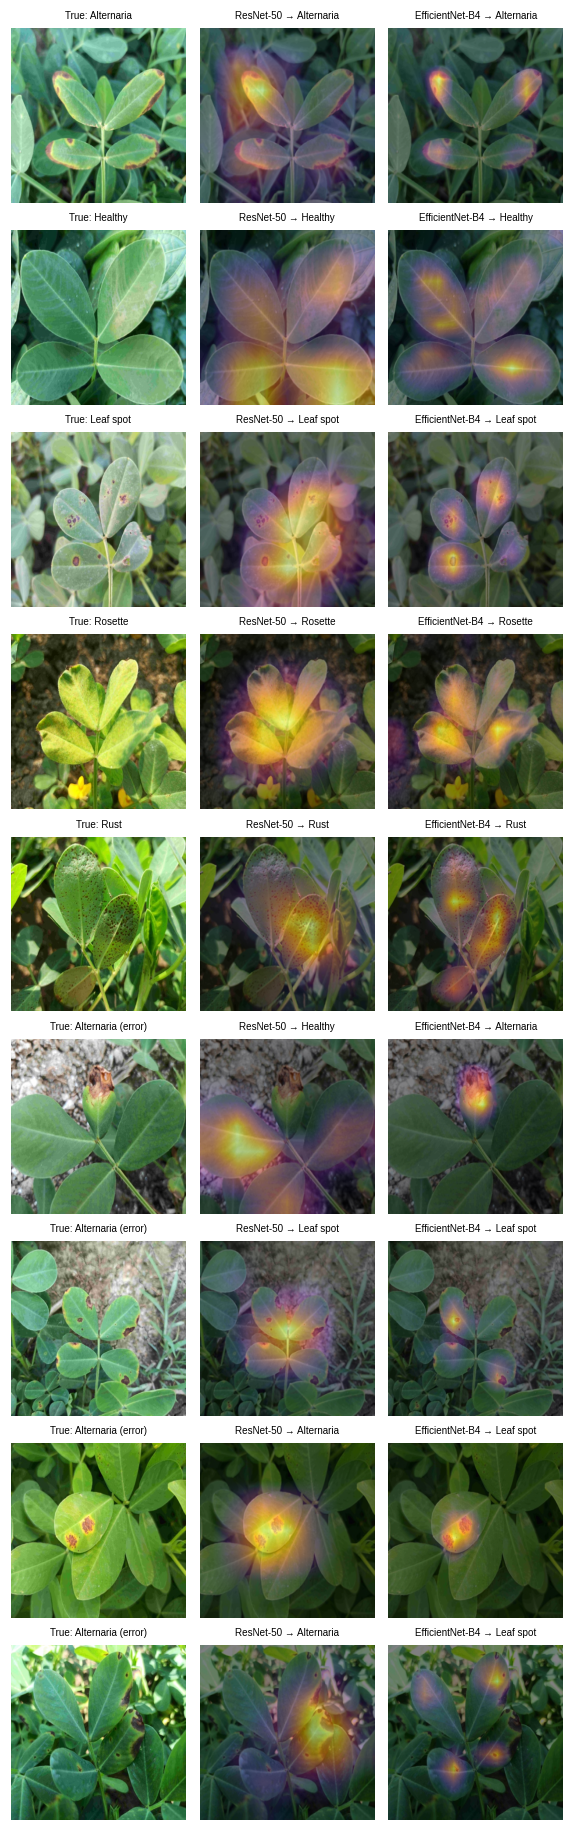

In [17]:
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T, torchvision.models as M

@dataclass
class Config:
    name: str
    backbone: str
    recipe: str
    aug: str = "A"
    sampler: bool = True
    class_weighted_loss: bool = True
    label_smoothing: float = 0.0
    optimizer: str = "adam"
    lr: float = 1e-3
    weight_decay: float = 1e-5
    scheduler: str = "onecycle"
    epochs: int = 25
    finetune: str = "partial"
    head: str = "mlp"
    batch_size: int = 32
    img_size: int = 224
    select_metric: str = "val_macro_f1"
    pretrained: bool = True
    split: str = "cv_splits"          # which split file in 02_splits/ (cv_splits = group-aware)
    notes: str = ""

def recipe_P(backbone, **kw):
    big = backbone == "efficientnet_b4"
    kw.setdefault("name", f"{backbone}__P")
    return Config(backbone=backbone, recipe="P", img_size=380 if big else 224, batch_size=16 if big else 32, **kw)

def recipe_B(backbone, **kw):
    big = backbone == "efficientnet_b4"
    kw.setdefault("name", f"{backbone}__B")
    return Config(backbone=backbone, recipe="B", aug="B", sampler=False, class_weighted_loss=False,
                  label_smoothing=0.2, optimizer="adamw", lr=1e-5, weight_decay=1e-4, scheduler="cosine_wr",
                  finetune="full", head="linear", img_size=380 if big else 224, batch_size=16 if big else 32, **kw)

BACKBONES = ["resnet50", "efficientnet_b0", "efficientnet_b4", "convnext_base"]
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

def get_transforms(aug, size):
    if aug == "A":    # Disease_CNN_Transfer_learning_RasNet_50.ipynb
        train = T.Compose([T.Resize((size, size)), T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(20),
                           T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
                           T.RandomAffine(degrees=0, translate=(0.1, 0.1)), T.ToTensor(), T.RandomErasing(p=0.2),
                           T.Normalize(MEAN, STD)])
    elif aug == "B":  # Disease-EfficientNet-B0/B4, Disease-ConvNeXt-Base
        train = T.Compose([T.RandomHorizontalFlip(p=0.5), T.RandomRotation(15), T.RandomResizedCrop(size, scale=(0.7, 1.0)),
                           T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
                           T.RandomAffine(degrees=0, translate=(0.1, 0.1)), T.RandomGrayscale(p=0.1), T.ToTensor(),
                           T.Normalize(MEAN, STD)])
    elif aug == "none":
        train = T.Compose([T.Resize((size, size)), T.ToTensor(), T.Normalize(MEAN, STD)])
    else:
        raise ValueError(aug)
    test = T.Compose([T.Resize((size, size)), T.ToTensor(), T.Normalize(MEAN, STD)])
    return train, test

def build_model(cfg, num_classes=5):
    def head(in_f):
        if cfg.head == "mlp":
            return nn.Sequential(nn.Linear(in_f, 512), nn.ReLU(), nn.Dropout(0.3), nn.Linear(512, num_classes))
        return nn.Linear(in_f, num_classes)
    b, pre = cfg.backbone, cfg.pretrained
    if b == "resnet50":
        m = M.resnet50(weights=M.ResNet50_Weights.IMAGENET1K_V1 if pre else None)
        m.fc = head(m.fc.in_features); trainable = ["layer4.", "fc."]
    elif b == "efficientnet_b0":
        m = M.efficientnet_b0(weights=M.EfficientNet_B0_Weights.IMAGENET1K_V1 if pre else None)
        m.classifier[1] = head(m.classifier[1].in_features); trainable = ["features.6.", "features.7.", "features.8.", "classifier."]
    elif b == "efficientnet_b4":
        m = M.efficientnet_b4(weights=M.EfficientNet_B4_Weights.IMAGENET1K_V1 if pre else None)
        m.classifier[1] = head(m.classifier[1].in_features); trainable = ["features.6.", "features.7.", "features.8.", "classifier."]
    elif b == "convnext_base":
        m = M.convnext_base(weights=M.ConvNeXt_Base_Weights.IMAGENET1K_V1 if pre else None)
        m.classifier[2] = head(m.classifier[2].in_features); trainable = ["features.6.", "features.7.", "classifier."]
    else:
        raise ValueError(b)
    if cfg.finetune == "partial":
        for n, p in m.named_parameters():
            p.requires_grad = any(n.startswith(t) for t in trainable)
    return m


DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def load_model(name, fold=0):
    cfgd = ALL[name][0]["m"]["config"]; cfg = Config(**{k: v for k, v in cfgd.items() if k in Config.__dataclass_fields__})
    cfg = replace(cfg, pretrained=False)
    m = build_model(cfg); sd = torch.load(D["models"] / name / f"r0_f{fold}.pt", map_location="cpu")
    m.load_state_dict({k: v.float() for k, v in sd.items()}); return m.to(DEV).eval(), cfg
def target_layer(m, backbone):
    return m.layer4 if backbone == "resnet50" else m.features[-1]
def gradcam(m, layer, x, cls):
    store = {}
    def fwd(_, __, out):
        store["a"] = out; out.register_hook(lambda g: store.__setitem__("g", g))
    h = layer.register_forward_hook(fwd)
    x = x.clone().requires_grad_(True); out = m(x); m.zero_grad(); out[0, cls].backward(); h.remove()
    w = store["g"].mean((2, 3), keepdim=True); cam = F.relu((w * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = cam - cam.min(); return (cam / (cam.max() + 1e-8)).detach().cpu().numpy(), int(out.argmax(1))

local_cache = Path(LOCAL_ROOT) / "cache448"
if GRADCAM_MODELS and not any(local_cache.rglob("*.jpg")):
    local_cache.parent.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(D["data"] / "groundnut_v2_cache448.zip") as z: z.extractall(LOCAL_ROOT)
gc_models = [n for n in GRADCAM_MODELS if (D["models"] / n / "r0_f0.pt").exists()]
if gc_models:
    MODELS_GC = {n: load_model(n) for n in gc_models}
    pr = {n: pooled(n) for n in gc_models}; pr = {n: p[p["fold"] == 0].set_index("image_id") for n, p in pr.items()}
    common = sorted(set.intersection(*[set(p.index) for p in pr.values()]))
    rel = dict(zip(idx["image_id"], idx["cache_rel"]))
    picks = []
    for k in range(K):
        ok = [i for i in common if all(pr[n].loc[i, "y_true"] == k and pr[n].loc[i, "y_pred"] == k for n in gc_models)]
        if ok: picks.append((ok[0], "correct"))
    wrong = [i for i in common if any(pr[n].loc[i, "y_pred"] != pr[n].loc[i, "y_true"] for n in gc_models)]
    picks += [(i, "misclassified") for i in wrong[:4]]
    fig, axes = plt.subplots(len(picks), 1 + len(gc_models), figsize=(1.75 * (1 + len(gc_models)), 1.85 * len(picks)))
    axes = np.atleast_2d(axes)
    for r_, (iid, kind) in enumerate(picks):
        img = Image.open(local_cache / rel[iid]).convert("RGB"); yt = int(pr[gc_models[0]].loc[iid, "y_true"])
        axes[r_, 0].imshow(img); axes[r_, 0].set_title(f"True: {SHORT[yt]}" + (" (error)" if kind == "misclassified" else ""), fontsize=6.5)
        for c_, n in enumerate(gc_models):
            m, cfg = MODELS_GC[n]
            tf = T.Compose([T.Resize((cfg.img_size, cfg.img_size)), T.ToTensor(), T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
            cam, pred = gradcam(m, target_layer(m, cfg.backbone), tf(img)[None].to(DEV), int(pr[n].loc[iid, "y_pred"]))
            axes[r_, c_ + 1].imshow(img.resize((cfg.img_size, cfg.img_size))); axes[r_, c_ + 1].imshow(cam, cmap="inferno", alpha=0.5)
            axes[r_, c_ + 1].set_title(f"{NICE[cfg.backbone]} → {SHORT[pred]}", fontsize=6.5)
        for a in axes[r_]: a.axis("off")
    fig.tight_layout(); save(fig, "Fig_gradcam")
else:
    print("No saved weights found for", GRADCAM_MODELS, "- Grad-CAM skipped.")

## 11. Research log (full precision) and the two results zips

In [18]:
def R(x):
    if isinstance(x, float): return repr(x)
    if isinstance(x, (list, tuple)): return "[" + ", ".join(R(v) for v in x) + "]"
    if isinstance(x, dict): return "{" + ", ".join(f"{k}: {R(v)}" for k, v in x.items()) + "}"
    return str(x)
L = [f"# Research log — {NOTEBOOK}", "", f"Run: {ENV['run_at']} | bootstrap resamples: {N_BOOT} | seed {SEED}",
     f"Split rule: {cv_meta}", "", "All numbers are written programmatically at full precision (Python repr).", ""]
for title, obj in EXACT.items():
    L += [f"## {title}", ""]
    if isinstance(obj, pd.DataFrame):
        L += ["```", obj.to_csv(index=False), "```", ""]
    else:
        for item in obj:
            L.append("- " + R(item))
        L.append("")
L += ["## Environment", "```", json.dumps(ENV, indent=2), "```"]
(D["logs"] / "research_log_NB04.md").write_text("\n".join(L))
print("research log written")

text_zip = Path(LOCAL_ROOT) / "NB04_results_text.zip"
with zipfile.ZipFile(text_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for p in TAB.glob("*.csv"): z.write(p, f"tables/{p.name}")
    for p in D["logs"].glob("research_log_*.md"): z.write(p, f"research_logs/{p.name}")
    for p in D["splits"].glob("*.json"): z.write(p, f"splits/{p.name}")
    for p in D["audit"].glob("*.csv"):
        if p.stat().st_size < 3e6: z.write(p, f"audit/{p.name}")
    for p in D["audit"].glob("NB01_report.*"): z.write(p, f"audit/{p.name}")
# figures zip for review: 300-dpi PNGs only (the TIFF and PDF files for submission stay in 07_figures/final/ on Drive)
fig_zip = Path(LOCAL_ROOT) / "NB04_results_figures.zip"
with zipfile.ZipFile(fig_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for p in FIG.glob("*.png"): z.write(p, f"figures/{p.name}")
    for p in D["figures"].glob("*.png"): z.write(p, f"figures_dataset/{p.name}")
    for name in ["closest_test_train_pairs_after_grouping.png", "embedding_combined_rule_pairs.png", "embedding_just_above.png",
                 "embedding_just_below.png"]:       # large contact sheets -> compressed JPEG copies
        if (D["audit"] / name).exists():
            im = Image.open(D["audit"] / name).convert("RGB"); buf = io.BytesIO(); im.save(buf, "JPEG", quality=82)
            z.writestr(f"audit/{Path(name).stem}.jpg", buf.getvalue())
for zp in (text_zip, fig_zip):
    shutil.copyfile(zp, D["results"] / zp.name); print(f"{zp.name}: {zp.stat().st_size/1e6:.1f} MB (copy in 04_results/)")
if IN_COLAB:
    from google.colab import files
    files.download(str(text_zip)); files.download(str(fig_zip))

research log written
NB04_results_text.zip: 0.1 MB (copy in 04_results/)
NB04_results_figures.zip: 19.3 MB (copy in 04_results/)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>